# Exploring the Data

Checking the data quality (missing values, duplicates, errors), analysing daily, weekly and monthly sales, identifying the busiest hours,
comparing the days of the week, looking at the best-selling and most profitable products, charts and first conclusions about customer demand.

In [1]:
import sys
from pathlib import Path

# VS Code can start the notebook from notebooks/ or from the project folder,
# so I look for the folder that contains src/ and add it to the path
here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "src").exists())
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.analysis import read_data, save_plot, save_table, check_close, quality_report

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load data

In [2]:
sales = read_data("processed", "clean_sales.csv")
raw_sales = read_data("simulated", "sales.csv")
daily = read_data("processed", "daily_sales.csv")
hourly = read_data("processed", "hourly_sales.csv")
products = read_data("raw", "products.csv")

for df in (sales, daily, hourly):
    df["date"] = pd.to_datetime(df["date"])

sales.head()

,date,hour,product_id,quantity,revenue,variable_cost,contribution_margin
0,2026-01-01,7,1,7,35,10.15,24.85
1,2026-01-01,7,2,1,5,1.45,3.55
2,2026-01-01,7,3,3,24,9.00,15.00
3,2026-01-01,7,4,8,72,27.04,44.96
4,2026-01-01,8,1,8,40,11.60,28.40


## 2. Data quality

In [3]:
quality_report({
    "Clean sales": sales,
    "Simulated sales": raw_sales,
    "Daily sales": daily,
    "Hourly sales": hourly,
    "Products": products,
})

,dataset,rows,columns,missing,duplicates
0,Clean sales,4480,7,0,0
1,Simulated sales,4480,6,0,0
2,Daily sales,90,7,0,0
3,Hourly sales,1170,6,0,0
4,Products,4,4,0,0


In [4]:
# basic rules the data must follow (the notebook stops with an error if one is broken)
assert (sales[["quantity", "revenue", "variable_cost"]] >= 0).all().all(), "Negative values found"
assert sales["hour"].between(7, 19).all(), "Sales outside opening hours"
assert sales["product_id"].isin(products["product_id"]).all(), "Unknown product id"
print("All basic checks passed.")

All basic checks passed.


## 3. Do the files agree with each other?
`daily_sales`, `hourly_sales` and `clean_sales` were all built from the same raw file, so their totals must be equal.

In [5]:
check_close(sales["revenue"].sum(), daily["revenue"].sum(), "Daily revenue = clean sales revenue")
check_close(sales["quantity"].sum(), hourly["quantity"].sum(), "Hourly quantity = clean sales quantity")
check_close(sales["contribution_margin"].sum(), daily["contribution_margin"].sum(), "Daily contribution = clean sales contribution")
check_close(sales["revenue"].sum(), (raw_sales["quantity"] * raw_sales["unit_price"]).sum(), "Raw and processed revenue")
check_close(sales["variable_cost"].sum(), (raw_sales["quantity"] * raw_sales["unit_cost"]).sum(), "Raw and processed variable costs")

OK  Daily revenue = clean sales revenue
OK  Hourly quantity = clean sales quantity
OK  Daily contribution = clean sales contribution
OK  Raw and processed revenue
OK  Raw and processed variable costs


## 4. Overall performance

In [6]:
total_revenue = sales["revenue"].sum()
total_items = sales["quantity"].sum()
total_variable_cost = sales["variable_cost"].sum()
total_contribution = sales["contribution_margin"].sum()

print(f"Period: {sales['date'].min().date()} to {sales['date'].max().date()}")
print(f"Total revenue: {total_revenue:,.2f} RON")
print(f"Items sold: {total_items:,.0f}")
print(f"Variable costs: {total_variable_cost:,.2f} RON")
print(f"Contribution margin: {total_contribution:,.2f} RON")
print(f"Average revenue per item: {total_revenue / total_items:.2f} RON")

Period: 2026-01-01 to 2026-03-31
Total revenue: 150,943.00 RON
Items sold: 21,917
Variable costs: 52,441.93 RON
Contribution margin: 98,501.07 RON
Average revenue per item: 6.89 RON


## 5. Daily sales

Average daily revenue: 1677.14 RON
Highest daily revenue: 2425 RON
Lowest daily revenue: 1099 RON


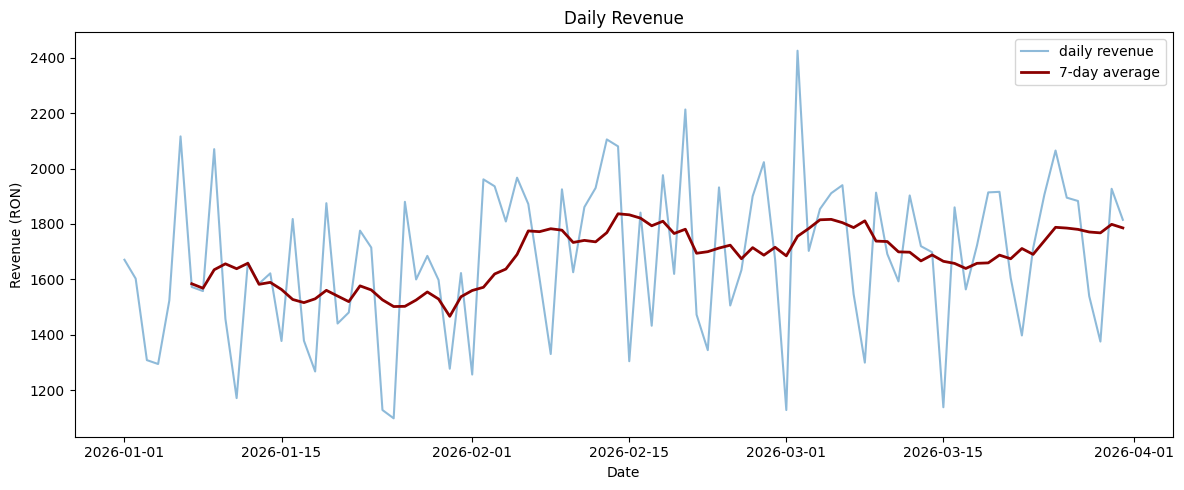

In [7]:
daily = daily.sort_values("date").copy()
daily["weekday_name"] = daily["date"].dt.day_name()
daily["month"] = daily["date"].dt.to_period("M").astype(str)
daily["revenue_7day_avg"] = daily["revenue"].rolling(7).mean()

print("Average daily revenue:", round(daily["revenue"].mean(), 2), "RON")
print("Highest daily revenue:", round(daily["revenue"].max(), 2), "RON")
print("Lowest daily revenue:", round(daily["revenue"].min(), 2), "RON")

plt.figure(figsize=(12, 5))
plt.plot(daily["date"], daily["revenue"], alpha=0.5, label="daily revenue")
plt.plot(daily["date"], daily["revenue_7day_avg"], color="darkred", linewidth=2, label="7-day average")
plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (RON)")
plt.legend()
save_plot("exploration_daily_revenue.png")

## 6. Weekdays vs weekends

In [8]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday_stats = (
    daily.groupby("weekday_name")
    .agg(days=("date", "size"), mean_revenue=("revenue", "mean"), mean_items=("quantity", "mean"))
    .reindex(weekday_order)
)
weekday_stats

,days,mean_revenue,mean_items
weekday_name,,,
Monday,13,"1,879.69",272.54
Tuesday,13,"1,686.31",246.69
Wednesday,12,"1,739.67",252.50
Thursday,13,"1,770.85",255.69
Friday,13,"1,858.15",270.23
Saturday,13,"1,547.54",224.62
Sunday,13,"1,262.62",183.08


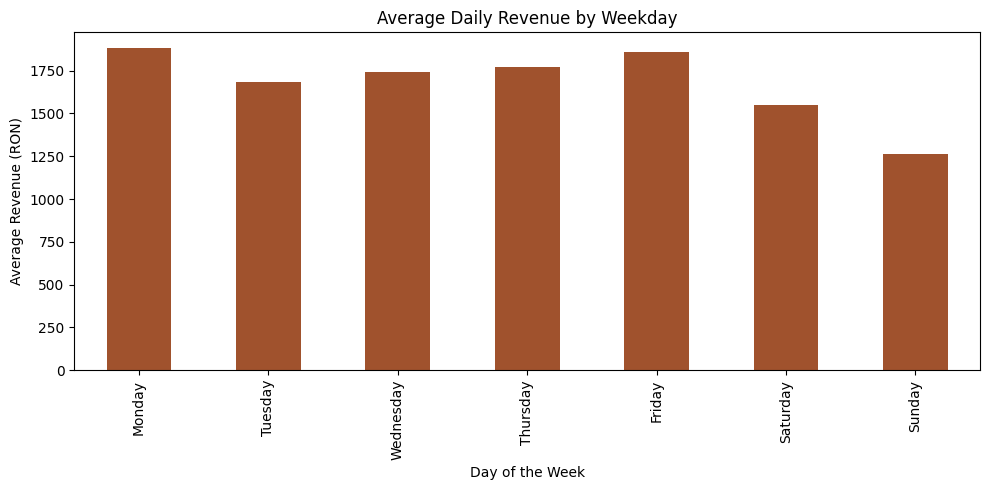

Weekend items vs weekday items: -21.5 %


In [9]:
weekday_stats["mean_revenue"].plot.bar(figsize=(10, 5), title="Average Daily Revenue by Weekday", color="sienna")
plt.xlabel("Day of the Week")
plt.ylabel("Average Revenue (RON)")
save_plot("exploration_weekday_average.png")

weekend_gap = daily.groupby("is_weekend")["quantity"].mean()
print("Weekend items vs weekday items:", round((weekend_gap[1] / weekend_gap[0] - 1) * 100, 1), "%")

## 7. Hourly demand

In [10]:
hour_stats = (
    hourly.groupby("hour")
    .agg(mean_items=("quantity", "mean"), mean_revenue=("revenue", "mean"), hours_observed=("date", "size"))
)
busiest_hour = hour_stats["mean_items"].idxmax()
print(f"Busiest hour: {busiest_hour}:00")
hour_stats

Busiest hour: 8:00


,mean_items,mean_revenue,hours_observed
hour,,,
7,19.16,129.91,90
8,34.42,234.23,90
9,26.97,182.96,90
10,20.02,138.19,90
11,16.64,116.98,90
12,19.66,136.13,90
13,19.86,138.62,90
14,14.74,101.43,90
15,14.48,100.47,90


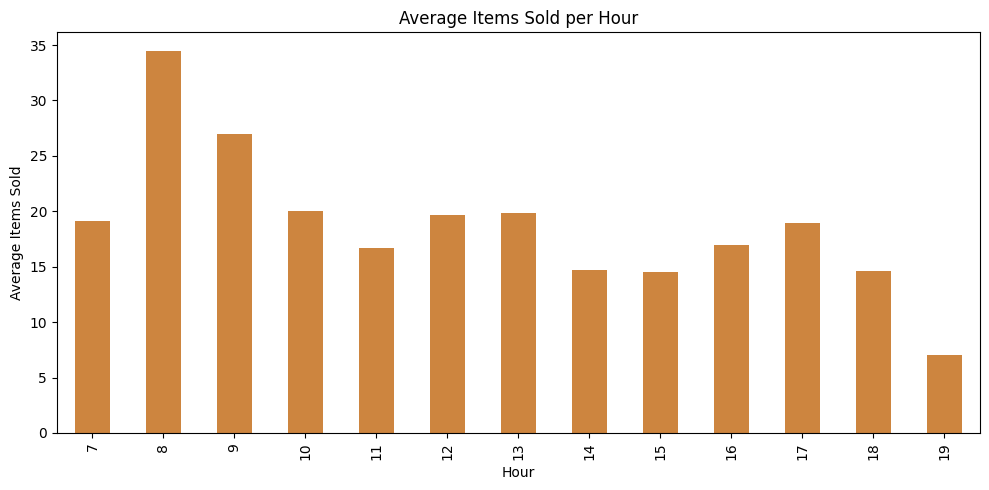

In [11]:
hour_stats["mean_items"].plot.bar(figsize=(10, 5), title="Average Items Sold per Hour", color="peru")
plt.xlabel("Hour")
plt.ylabel("Average Items Sold")
save_plot("exploration_hourly_demand.png")

## 8. Product performance

In [12]:
product_stats = sales.groupby("product_id", as_index=False).agg(
    items=("quantity", "sum"),
    revenue=("revenue", "sum"),
    contribution=("contribution_margin", "sum"),
)
product_stats = product_stats.merge(
    products[["product_id", "product_name", "category"]], on="product_id", validate="one_to_one"
)
product_stats["items_share_pct"] = product_stats["items"] / product_stats["items"].sum() * 100
product_stats["revenue_share_pct"] = product_stats["revenue"] / product_stats["revenue"].sum() * 100
product_stats = product_stats.sort_values("revenue", ascending=False)
product_stats

,product_id,items,revenue,contribution,product_name,category,items_share_pct,revenue_share_pct
2,3,6898,55184,"34,490.00",Cappuccino,Coffee,31.47,36.56
3,4,5166,46494,"29,032.92",Latte,Coffee,23.57,30.80
0,1,6702,33510,"23,792.10",Espresso,Coffee,30.58,22.20
1,2,3151,15755,"11,186.05",Americano,Coffee,14.38,10.44


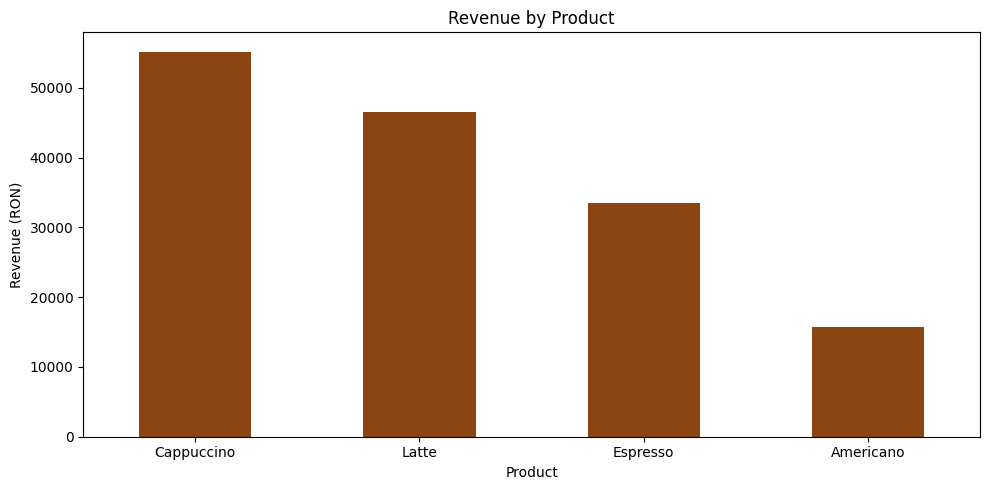

In [13]:
product_stats.plot.bar(x="product_name", y="revenue", figsize=(10, 5), legend=False,
                       title="Revenue by Product", color="saddlebrown", rot=0)
plt.xlabel("Product")
plt.ylabel("Revenue (RON)")
save_plot("exploration_product_revenue.png")

## 9. Monthly sales

In [14]:
monthly_sales = daily.groupby("month", as_index=False).agg(
    revenue=("revenue", "sum"), items=("quantity", "sum"), days=("date", "size")
)
monthly_sales["items_per_day"] = monthly_sales["items"] / monthly_sales["days"]
monthly_sales["revenue_per_item"] = monthly_sales["revenue"] / monthly_sales["items"]
monthly_sales

,month,revenue,items,days,items_per_day,revenue_per_item
0,2026-01,48240,7010,31,226.13,6.88
1,2026-02,49137,7113,28,254.04,6.91
2,2026-03,53566,7794,31,251.42,6.87


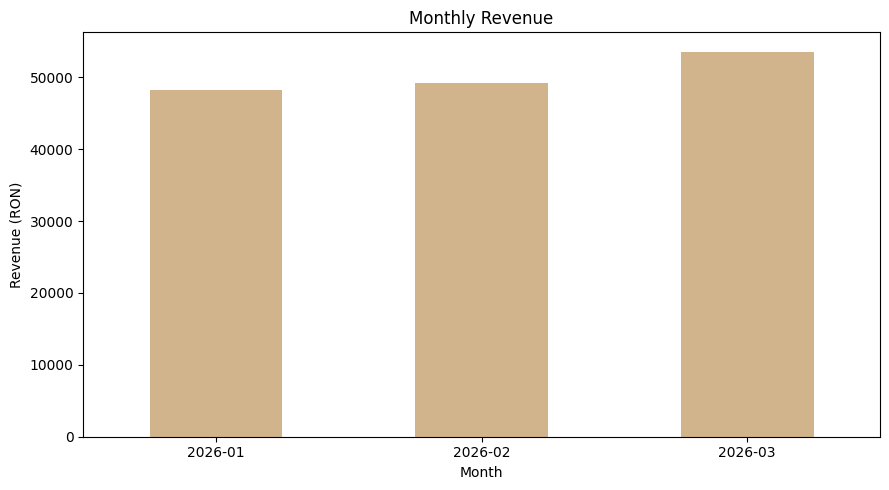

In [15]:
monthly_sales.plot.bar(x="month", y="revenue", figsize=(9, 5), legend=False,
                       title="Monthly Revenue", color="tan", rot=0)
plt.xlabel("Month")
plt.ylabel("Revenue (RON)")
save_plot("exploration_monthly_revenue.png")

## 10. Export the tables

In [16]:
save_table(weekday_stats.reset_index(), "exploration_weekdays.csv")
save_table(hour_stats.reset_index(), "exploration_hours.csv")
save_table(product_stats, "exploration_products.csv")
save_table(monthly_sales, "exploration_months.csv")

Saved: reports/tables/exploration_weekdays.csv
Saved: reports/tables/exploration_hours.csv
Saved: reports/tables/exploration_products.csv
Saved: reports/tables/exploration_months.csv


## What I found
The café is a morning business: 08:00 is the busiest hour by far, and weekends sell about 21% fewer items than weekdays.
Cappuccino is the star (36.6% of revenue). Espresso is about 31% of the cups but only 22% of the revenue, so what sells the most
is not what brings the most money. The data is clean and the totals match between files.